# BeanScope — Dry Bean variety classification (ML Assignment 2)

This notebook walks through the full experiment: data understanding, a leakage-free split, the five required
classifiers, the six evaluation metrics, the comparison, and a check that the saved models in `model/` reproduce the
same numbers. `train_models.py` runs the same steps as a script and writes the saved models used by the Streamlit app.

**Run order:** `python train_models.py` first (creates `data/dry_bean_clean.csv`, `test_data.csv` and `model/`), then run this notebook top to bottom.

In [1]:
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold

from bean_utils import FEATURES, TARGET, METRIC_COLUMNS, MODEL_FILES, load_dry_bean, score_predictions, confusion_frame, per_class_table
from train_models import candidate_models, with_probabilities, SEED, TEST_SIZE

pd.set_option("display.precision", 4)

Matplotlib is building the font cache; this may take a moment.


## 1. Load the data

In [2]:
raw = load_dry_bean()          # reads the original data/Dry_Bean_Dataset.arff (downloads it from UCI if missing)
print("Shape:", raw.shape)
raw.head()

Shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395.0,610.291,208.1781,173.8887,1.1972,0.5498,28715.0,190.1411,0.7639,0.9889,0.9580,0.9134,0.0073,0.0031,0.8342,0.9987,SEKER
1,28734.0,638.018,200.5248,182.7344,1.0974,0.4118,29172.0,191.2728,0.7840,0.9850,0.8870,0.9539,0.0070,0.0036,0.9099,0.9984,SEKER
2,29380.0,624.110,212.8261,175.9311,1.2097,0.5627,29690.0,193.4109,0.7781,0.9896,0.9478,0.9088,0.0072,0.0030,0.8259,0.9991,SEKER
3,30008.0,645.884,210.5580,182.5165,1.1536,0.4986,30724.0,195.4671,0.7827,0.9767,0.9039,0.9283,0.0070,0.0032,0.8618,0.9942,SEKER
4,30140.0,620.134,201.8479,190.2793,1.0608,0.3337,30417.0,195.8965,0.7731,0.9909,0.9849,0.9705,0.0067,0.0037,0.9419,0.9992,SEKER


## 2. Data understanding

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  float64
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  float64
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(16), str(1)


In [4]:
print("Missing values per column:\n", raw.isna().sum()[raw.isna().sum() > 0] if raw.isna().any().any() else "none")
print("Exact duplicate rows:", raw.duplicated().sum())

Missing values per column:
 none
Exact duplicate rows: 68


In [5]:
counts = raw[TARGET].value_counts()
pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)})

,count,percent
Class,,
DERMASON,3546,26.05
SIRA,2636,19.37
SEKER,2027,14.89
HOROZ,1928,14.17
CALI,1630,11.98
BARBUNYA,1322,9.71
BOMBAY,522,3.84


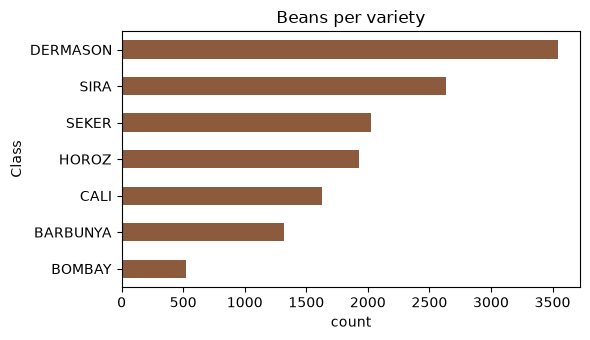

In [6]:
ax = counts.sort_values().plot.barh(color="#8c5a3c", figsize=(6, 3.5), title="Beans per variety")
ax.set_xlabel("count"); plt.tight_layout(); plt.show()

In [7]:
raw[FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.2845,29324.0957,20420.0000,36328.0000,44652.0000,61332.0000,254616.0000
Perimeter,13611.0,855.2835,214.2897,524.7360,703.5235,794.9410,977.2130,1985.3700
MajorAxisLength,13611.0,320.1419,85.6942,183.6012,253.3036,296.8834,376.4950,738.8602
MinorAxisLength,13611.0,202.2707,44.9701,122.5127,175.8482,192.4317,217.0317,460.1985
AspectRatio,13611.0,1.5832,0.2467,1.0249,1.4323,1.5511,1.7071,2.4303
Eccentricity,13611.0,0.7509,0.0920,0.2190,0.7159,0.7644,0.8105,0.9114
ConvexArea,13611.0,53768.2002,29774.9158,20684.0000,36714.5000,45178.0000,62294.0000,263261.0000
EquivDiameter,13611.0,253.0642,59.1771,161.2438,215.0680,238.4380,279.4465,569.3744
Extent,13611.0,0.7497,0.0491,0.5553,0.7186,0.7599,0.7869,0.8662
Solidity,13611.0,0.9871,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


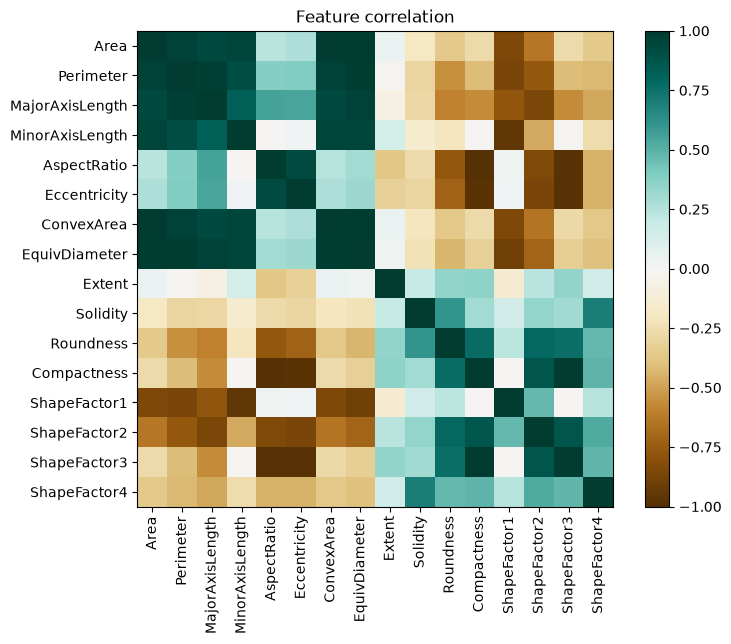

Most strongly correlated feature pairs:
 Area          ConvexArea       1.000
Compactness   ShapeFactor3     0.999
Perimeter     EquivDiameter    0.991
AspectRatio   Compactness      0.988
ConvexArea    EquivDiameter    0.985
Area          EquivDiameter    0.985
Eccentricity  ShapeFactor3     0.981
AspectRatio   ShapeFactor3     0.979
dtype: float64


In [8]:
corr = raw[FEATURES].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90); ax.set_yticks(range(len(FEATURES)), FEATURES)
fig.colorbar(im); ax.set_title("Feature correlation"); plt.tight_layout(); plt.show()

high = (corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False))
print("Most strongly correlated feature pairs:\n", high.head(8).round(3))

**Notes to write after running:** the class balance (which varieties are rare), the scale differences between
features (e.g. `Area` in tens of thousands vs `ShapeFactor` values below 0.01 — so distance-based models need scaling),
and how many feature pairs are almost perfectly correlated (relevant for Naive Bayes, which assumes independence).

## 3. Cleaning and train/test split
Duplicates are dropped *before* splitting so an identical bean cannot appear in both the training and test rows.

In [9]:
data = raw.dropna().drop_duplicates().reset_index(drop=True)
print("Rows used:", len(data))
X, y = data[FEATURES], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({"train %": y_train.value_counts(normalize=True) * 100,
              "test %": y_test.value_counts(normalize=True) * 100}).round(2)

Rows used: 13543
Train: (10834, 16)  Test: (2709, 16)


,train %,test %
Class,,
DERMASON,26.19,26.17
SIRA,19.47,19.45
SEKER,14.96,14.99
HOROZ,13.73,13.73
CALI,12.04,12.03
BARBUNYA,9.76,9.78
BOMBAY,3.86,3.84


## 4. The five models
Each model is a scikit-learn `Pipeline` (scaling is inside the pipeline, fitted on training rows only). A small grid is searched with 5-fold stratified CV on the **training** rows, scored by macro F1.

In [10]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
specs = candidate_models()
fitted, results = {}, {}

def fit_and_score(name):
    pipe, grid = specs[name]
    search = GridSearchCV(pipe, grid, scoring="f1_macro", cv=folds, n_jobs=-1).fit(X_train, y_train)
    best = search.best_estimator_
    if name == "Support Vector Machine":
        best = with_probabilities(best).fit(X_train, y_train)
    pred, proba = best.predict(X_test), best.predict_proba(X_test)
    fitted[name] = best
    results[name] = score_predictions(y_test, pred, proba, best.classes_)
    print(name, "| best params:", search.best_params_, "| CV macro-F1:", round(search.best_score_, 4))
    return pd.Series(results[name]).round(4)

### Logistic Regression

In [11]:
fit_and_score("Logistic Regression")

Logistic Regression | best params: {'clf__C': 50.0} | CV macro-F1: 0.9377


Accuracy     0.9203
AUC          0.9949
Precision    0.9319
Recall       0.9297
F1           0.9306
MCC          0.9037
dtype: float64

### Decision Tree

In [12]:
fit_and_score("Decision Tree")

Decision Tree | best params: {'clf__max_depth': 10, 'clf__min_samples_leaf': 10} | CV macro-F1: 0.9238


Accuracy     0.9044
AUC          0.9797
Precision    0.9179
Recall       0.9166
F1           0.9171
MCC          0.8844
dtype: float64

### K-Nearest Neighbours

In [13]:
fit_and_score("K-Nearest Neighbours")

K-Nearest Neighbours | best params: {'clf__n_neighbors': 11, 'clf__weights': 'distance'} | CV macro-F1: 0.9374


Accuracy     0.9147
AUC          0.9888
Precision    0.9292
Recall       0.9257
F1           0.9271
MCC          0.8969
dtype: float64

### Gaussian Naive Bayes

In [14]:
fit_and_score("Gaussian Naive Bayes")

Gaussian Naive Bayes | best params: {'clf__var_smoothing': 1e-09} | CV macro-F1: 0.7632


Accuracy     0.7630
AUC          0.9670
Precision    0.7736
Recall       0.7685
F1           0.7669
MCC          0.7143
dtype: float64

### Support Vector Machine

In [15]:
fit_and_score("Support Vector Machine")

Support Vector Machine | best params: {'clf__C': 10.0} | CV macro-F1: 0.9437


Accuracy     0.9240
AUC          0.9904
Precision    0.9360
Recall       0.9344
F1           0.9351
MCC          0.9080
dtype: float64

## 5. Comparison of all five models

In [16]:
table = pd.DataFrame(results).T[METRIC_COLUMNS]
table.index.name = "ML Model Name"
display(table.round(4))
print("Leader per metric:")
for m in METRIC_COLUMNS:
    print(f"  {m:<9} {table[m].idxmax()}  ({table[m].max():.4f})")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9203,0.9949,0.9319,0.9297,0.9306,0.9037
Decision Tree,0.9044,0.9797,0.9179,0.9166,0.9171,0.8844
K-Nearest Neighbours,0.9147,0.9888,0.9292,0.9257,0.9271,0.8969
Gaussian Naive Bayes,0.7630,0.9670,0.7736,0.7685,0.7669,0.7143
Support Vector Machine,0.9240,0.9904,0.9360,0.9344,0.9351,0.9080


Leader per metric:
  Accuracy  Support Vector Machine  (0.9240)
  AUC       Logistic Regression  (0.9949)
  Precision Support Vector Machine  (0.9360)
  Recall    Support Vector Machine  (0.9344)
  F1        Support Vector Machine  (0.9351)
  MCC       Support Vector Machine  (0.9080)


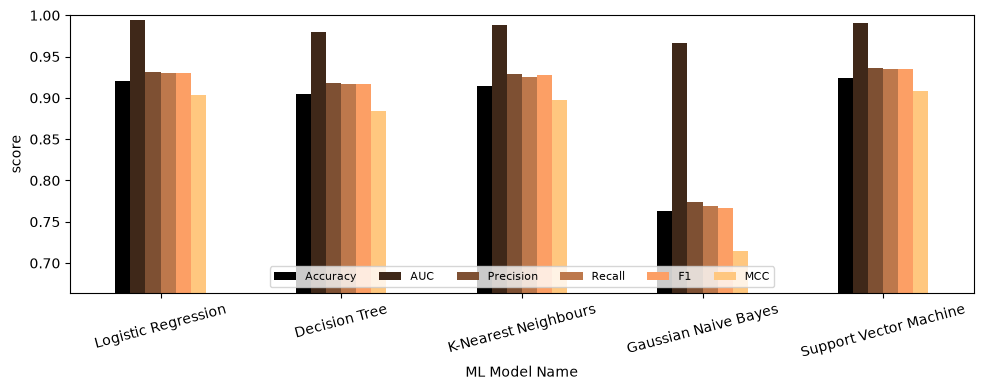

In [17]:
ax = table.plot.bar(figsize=(10, 4), ylim=(max(0, table.values.min() - 0.05), 1.0), colormap="copper")
ax.set_ylabel("score"); ax.legend(ncol=6, fontsize=8, loc="lower center"); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 6. Confusion matrices and per-class reports

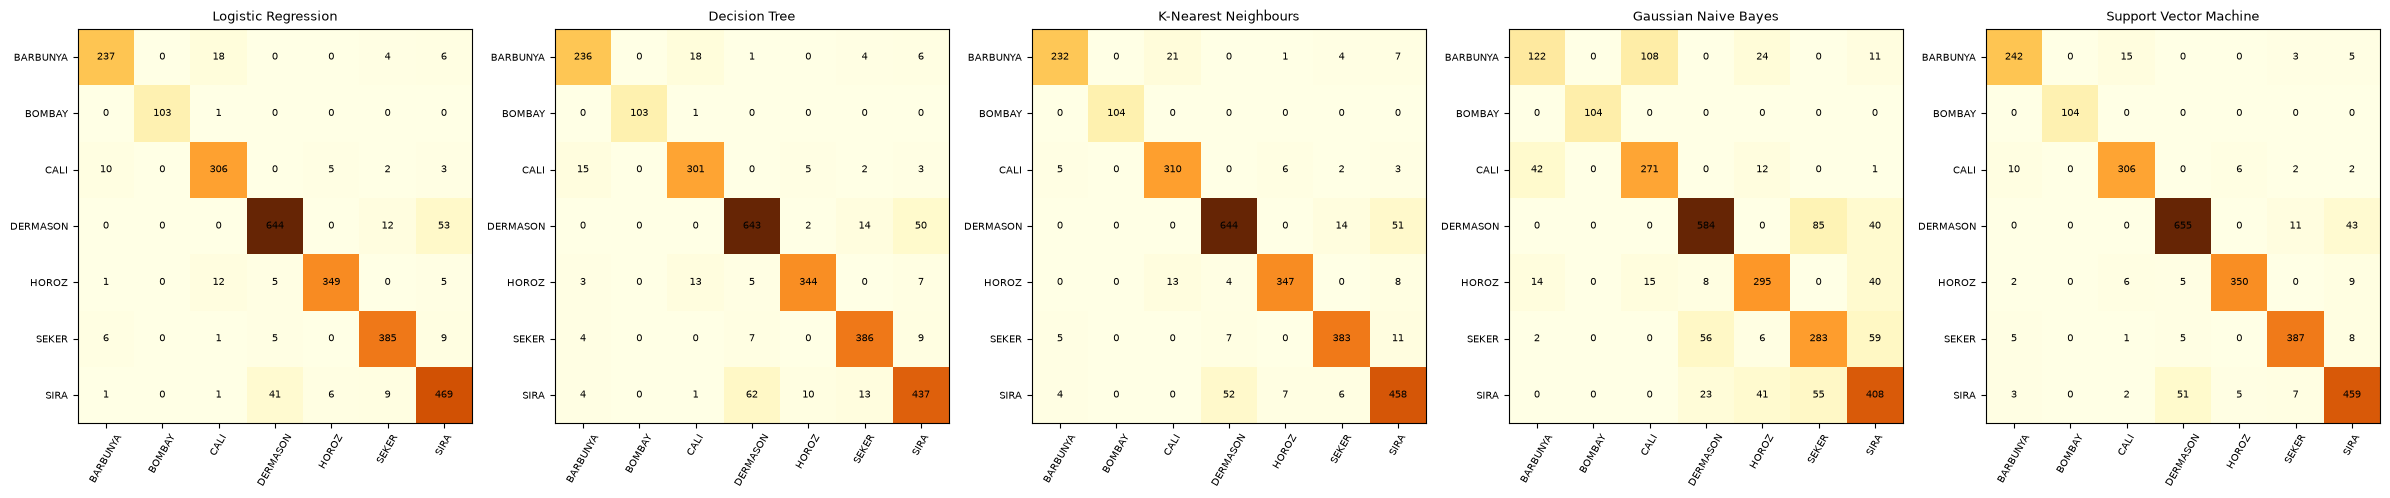

In [18]:
labels = sorted(y.unique())
fig, axes = plt.subplots(1, 5, figsize=(24, 4.8))
for ax, (name, model) in zip(axes, fitted.items()):
    cm = confusion_frame(y_test, model.predict(X_test), labels)
    ax.imshow(cm.values, cmap="YlOrBr")
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, cm.values[i, j], ha="center", va="center", fontsize=7)
    ax.set_xticks(range(len(labels)), labels, rotation=60, fontsize=7); ax.set_yticks(range(len(labels)), labels, fontsize=7)
    ax.set_title(name, fontsize=9)
plt.tight_layout(); plt.show()

In [19]:
for name, model in fitted.items():
    print("=" * 20, name)
    print(per_class_table(y_test, model.predict(X_test)).round(3))

==================== Logistic Regression
              precision  recall  f1-score  support
BARBUNYA          0.929   0.894     0.912      265
BOMBAY            1.000   0.990     0.995      104
CALI              0.903   0.939     0.920      326
DERMASON          0.927   0.908     0.917      709
HOROZ             0.969   0.938     0.954      372
SEKER             0.934   0.948     0.941      406
SIRA              0.861   0.890     0.875      527
macro avg         0.932   0.930     0.931     2709
weighted avg      0.921   0.920     0.920     2709
==================== Decision Tree
              precision  recall  f1-score  support
BARBUNYA          0.901   0.891     0.896      265
BOMBAY            1.000   0.990     0.995      104
CALI              0.901   0.923     0.912      326
DERMASON          0.896   0.907     0.901      709
HOROZ             0.953   0.925     0.939      372
SEKER             0.921   0.951     0.936      406
SIRA              0.854   0.829     0.841      527
macro 

              precision  recall  f1-score  support
BARBUNYA          0.924   0.913     0.918      265
BOMBAY            1.000   1.000     1.000      104
CALI              0.927   0.939     0.933      326
DERMASON          0.915   0.924     0.919      709
HOROZ             0.970   0.941     0.955      372
SEKER             0.944   0.953     0.949      406
SIRA              0.873   0.871     0.872      527
macro avg         0.936   0.934     0.935     2709
weighted avg      0.924   0.924     0.924     2709


## 7. Observations

*Fill this in from **your** results above (these sentences are what earns the 3 observation marks).* For each model note:
its Accuracy/F1/MCC versus the others, which varieties it confuses (from the confusion matrix), and *why* that fits how
the algorithm works (e.g. scaling for KNN/SVM/LR, independence assumption for Naive Bayes, axis-aligned splits for the tree).
Then name the overall winner using MCC and macro-F1, not accuracy alone.

## 8. Saved-model check
The Streamlit app uses the files in `model/`. Here we load them, score them on `test_data.csv`, and confirm they reproduce `metrics_summary.csv` written by `train_models.py`. (A refit in this notebook can differ from the saved model on a handful of rows, e.g. Logistic Regression with a large C, because of floating-point order in multi-threaded maths; the saved files are what the app and the README use.)

In [20]:
saved_test = pd.read_csv("test_data.csv")
summary = pd.read_csv("metrics_summary.csv", index_col=0)
Xs, ys = saved_test[FEATURES], saved_test[TARGET]
print("test_data.csv rows:", len(saved_test), "| same size as this split:", len(saved_test) == len(X_test))
for name, fname in MODEL_FILES.items():
    loaded = joblib.load(f"model/{fname}")
    s = pd.Series(score_predictions(ys, loaded.predict(Xs), loaded.predict_proba(Xs), loaded.classes_)).round(4)
    same_pred = (loaded.predict(X_test) == fitted[name].predict(X_test)).mean()
    print(f"{name:<24} matches metrics_summary.csv: {bool((s == summary.loc[name]).all())} | agreement with notebook refit: {same_pred:.2%}")
print(json.load(open("model/metadata.json"))["versions"])

test_data.csv rows: 2709 | same size as this split: True
Logistic Regression      matches metrics_summary.csv: True | agreement with notebook refit: 100.00%
Decision Tree            matches metrics_summary.csv: True | agreement with notebook refit: 100.00%
K-Nearest Neighbours     matches metrics_summary.csv: True | agreement with notebook refit: 100.00%
Gaussian Naive Bayes     matches metrics_summary.csv: True | agreement with notebook refit: 100.00%


Support Vector Machine   matches metrics_summary.csv: True | agreement with notebook refit: 100.00%
{'python': '3.12.10', 'scikit-learn': '1.9.1', 'pandas': '3.0.5', 'numpy': '2.5.3', 'joblib': '1.6.0'}


## 9. Run the app
```bash
streamlit run app.py
```
The app loads these saved pipelines and scores the uploaded CSV; it never calls `fit()`.